<a href="https://colab.research.google.com/github/MaineCalabrezi13/Classificacao-Cancer-Mama-ML/blob/main/Modelos_Unidos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
# Importação de bibliotecas essenciais
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pré-processamento e Modelagem
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Modelos Supervisionados (SVM, Árvore de Decisão, Random Forest e Ensemble Adicional)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

# Métricas de Avaliação Supervisionada
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)

# Algoritmos Não Supervisionados e Redução de Dimensionalidade
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Configurações visuais do Matplotlib / Seaborn
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


In [16]:
# Célula 2: Carga, Inspeção e Estruturação do Dataset
data = load_breast_cancer(as_frame=True)
df = data.frame
features_num = data.feature_names

# Ajuste no target: 1 = Maligno, 0 = Benigno
df['diagnosis_numeric'] = df['target'].map({0: 1, 1: 0})
df['diagnosis_label'] = df['diagnosis_numeric'].map({1: 'Maligno', 0: 'Benigno'})

print("Dataset carregado com sucesso!")
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.")

Dataset carregado com sucesso!
Dimensões do dataset: 569 linhas e 33 colunas.


=== 1. TIPOS DE DADOS E ESTRUTURA ===
float64    30
int64       2
object      1
Name: count, dtype: int64

=== 2. VERIFICAÇÃO DE VALORES AUSENTES ===
Empty DataFrame
Columns: [Qtd_Nulos, Pct_Nulos (%)]
Index: []
Total de valores nulos no dataset inteiro: 0

=== 3. DISTRIBUIÇÃO DA VARIÁVEL-ALVO (DIAGNÓSTICO) ===
                 Contagem  Percentual (%)
diagnosis_label                          
Benigno               357           62.74
Maligno               212           37.26


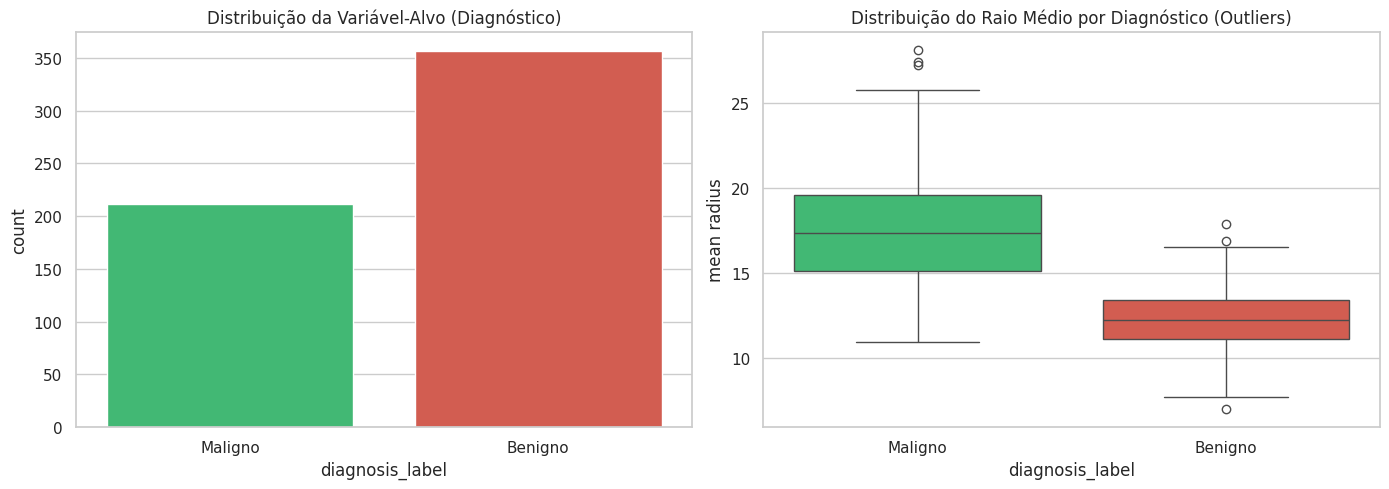

In [17]:
# Célula 3: Análise Exploratória de Dados (EDA)
print("=== 1. TIPOS DE DADOS E ESTRUTURA ===")
print(df.dtypes.value_counts())

print("\n=== 2. VERIFICAÇÃO DE VALORES AUSENTES ===")
nulos = df.isnull().sum()
pct_nulos = (df.isnull().sum() / len(df)) * 100
df_nulos = pd.DataFrame({'Qtd_Nulos': nulos, 'Pct_Nulos (%)': pct_nulos})
print(df_nulos[df_nulos['Qtd_Nulos'] > 0])
print("Total de valores nulos no dataset inteiro:", df.isnull().sum().sum())

print("\n=== 3. DISTRIBUIÇÃO DA VARIÁVEL-ALVO (DIAGNÓSTICO) ===")
dist_target = df['diagnosis_label'].value_counts()
pct_target = df['diagnosis_label'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Contagem': dist_target, 'Percentual (%)': pct_target.round(2)}))

# Visualização de Gráficos de EDA
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x='diagnosis_label', data=df, ax=axes[0], palette=['#2ecc71', '#e74c3c'], hue='diagnosis_label', legend=False)
axes[0].set_title('Distribuição da Variável-Alvo (Diagnóstico)')

sns.boxplot(x='diagnosis_label', y='mean radius', data=df, ax=axes[1], palette=['#2ecc71', '#e74c3c'], hue='diagnosis_label', legend=False)
axes[1].set_title('Distribuição do Raio Médio por Diagnóstico (Outliers)')
plt.tight_layout()
plt.show()

In [18]:
# Célula 4: Pré-processamento e Divisão em Treino, Validação e Teste
X = df[features_num].copy()
y = df['diagnosis_numeric'].copy()

# Divisão inicial: Separa 20% para Teste final e 80% para (Treino + Validação)
X_train_val, X_test_raw, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Divide os 80% restantes em Treino (60% do total) e Validação (20% do total)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

print(f"Dimensões do Conjunto de Treino: {X_train_raw.shape}")
print(f"Dimensões do Conjunto de Validação: {X_val_raw.shape}")
print(f"Dimensões do Conjunto de Teste: {X_test_raw.shape}")

Dimensões do Conjunto de Treino: (341, 30)
Dimensões do Conjunto de Validação: (114, 30)
Dimensões do Conjunto de Teste: (114, 30)


Testando k = 2 | Silhouette Score: 0.3462 | Inércia: 6856.86
Testando k = 3 | Silhouette Score: 0.3137 | Inércia: 5963.06
Testando k = 4 | Silhouette Score: 0.2880 | Inércia: 5463.11
Testando k = 5 | Silhouette Score: 0.1593 | Inércia: 5034.81
Testando k = 6 | Silhouette Score: 0.1638 | Inércia: 4684.62

=> O melhor K selecionado foi: K = 2 (com Silhouette Score de 0.3462)


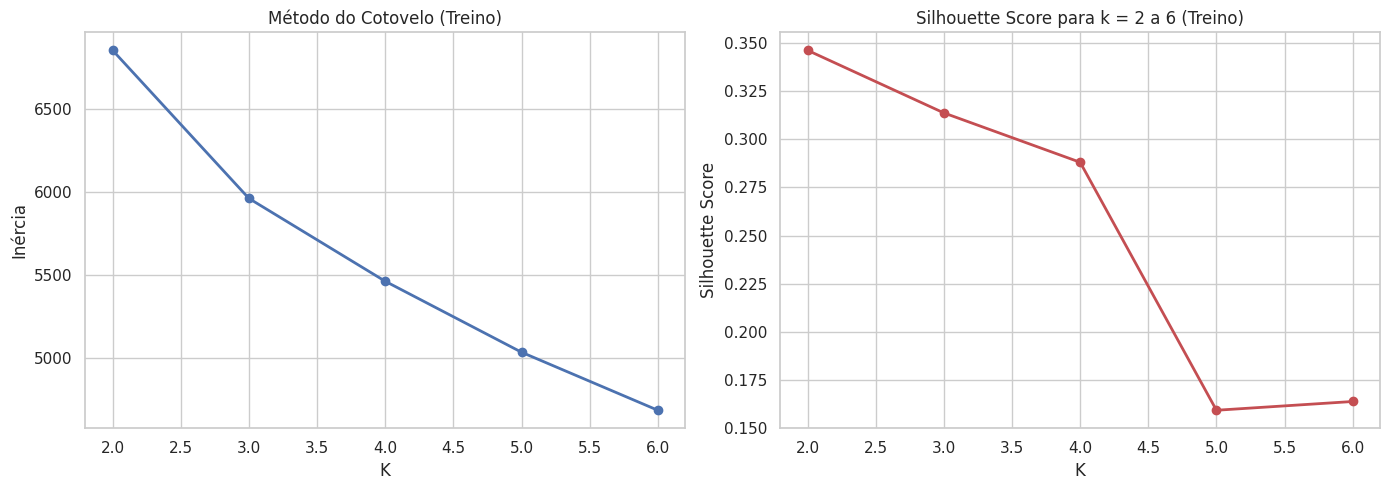

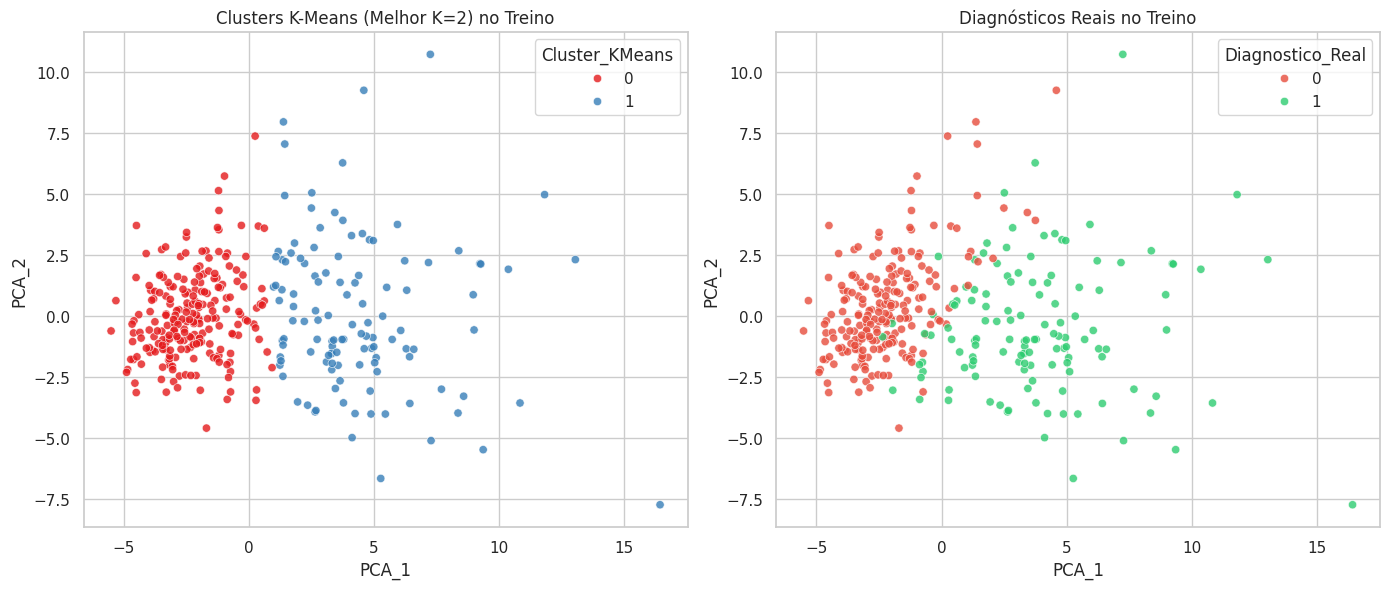

In [19]:
# Célula 5: Aprendizado Não Supervisionado (K-Means com testes de k=2 a 6, PCA e Feature Engineering)
# 1. Padronização estritamente sobre o Treino para evitar Data Leakage
scaler_kmeans = StandardScaler()
X_train_scaled = scaler_kmeans.fit_transform(X_train_raw)
X_val_scaled = scaler_kmeans.transform(X_val_raw)
X_test_scaled = scaler_kmeans.transform(X_test_raw)

# 2. Testes de K = 2, 3, 4, 5, 6 e avaliação por Silhouette Score
k_range = [2, 3, 4, 5, 6]
silhouette_scores = []
inertia = []

for k in k_range:
    km_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = km_test.fit_predict(X_train_scaled)
    score = silhouette_score(X_train_scaled, cluster_labels)
    silhouette_scores.append(score)
    inertia.append(km_test.inertia_)
    print(f"Testando k = {k} | Silhouette Score: {score:.4f} | Inércia: {km_test.inertia_:.2f}")

# Selecionando automaticamente o melhor K com base no maior Silhouette Score
best_k = k_range[np.argmax(silhouette_scores)]
print(f"\n=> O melhor K selecionado foi: K = {best_k} (com Silhouette Score de {max(silhouette_scores):.4f})")

# Visualização dos testes de K
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_range, inertia, 'bo-', linewidth=2)
axes[0].set_title('Método do Cotovelo (Treino)')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Inércia')

axes[1].plot(k_range, silhouette_scores, 'ro-', linewidth=2)
axes[1].set_title('Silhouette Score para k = 2 a 6 (Treino)')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

# 3. K-Means com o best_k otimizado para extração de atributos derivados (Cluster-based features)
kmeans_model = KMeans(n_clusters=best_k, random_state=42, n_init=20)

# Extração das distâncias aos centroides (gerando novas colunas de features para treino, validação e teste)
X_train_cluster_dist = kmeans_model.fit_transform(X_train_scaled)
X_val_cluster_dist = kmeans_model.transform(X_val_scaled)
X_test_cluster_dist = kmeans_model.transform(X_test_scaled)

cluster_feature_names = [f'dist_to_cluster_{i}' for i in range(best_k)]

# Montando novos DataFrames incluindo as features de cluster
X_train_aug = pd.DataFrame(X_train_scaled, columns=features_num, index=X_train_raw.index)
X_val_aug = pd.DataFrame(X_val_scaled, columns=features_num, index=X_val_raw.index)
X_test_aug = pd.DataFrame(X_test_scaled, columns=features_num, index=X_test_raw.index)

for idx, col in enumerate(cluster_feature_names):
    X_train_aug[col] = X_train_cluster_dist[:, idx]
    X_val_aug[col] = X_val_cluster_dist[:, idx]
    X_test_aug[col] = X_test_cluster_dist[:, idx]

# 4. Redução de Dimensionalidade com PCA para Visualização 2D
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

df_pca = pd.DataFrame(X_train_pca, columns=['PCA_1', 'PCA_2'])
df_pca['Cluster_KMeans'] = kmeans_model.labels_
df_pca['Diagnostico_Real'] = y_train.values

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(x='PCA_1', y='PCA_2', hue='Cluster_KMeans', data=df_pca, palette='Set1', ax=axes[0], alpha=0.8, legend='full')
axes[0].set_title(f'Clusters K-Means (Melhor K={best_k}) no Treino')

sns.scatterplot(x='PCA_1', y='PCA_2', hue='Diagnostico_Real', data=df_pca, palette=['#e74c3c', '#2ecc71'], ax=axes[1], alpha=0.8, legend='full')
axes[1].set_title('Diagnósticos Reais no Treino')
plt.tight_layout()
plt.show()

In [21]:
# Célula 6: Treinamento, Avaliação Completa com Múltiplas Métricas e Validação Cruzada
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Árvore de Decisão": DecisionTreeClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Random Forest (Ensemble 1)": RandomForestClassifier(random_state=42),
    "Gradient Boosting (Ensemble 2)": GradientBoostingClassifier(random_state=42)
}

metricas_lista = []

print("=== TREINAMENTO E AVALIAÇÃO MULTI-MÉTRICA ===")
for name, model in models.items():
    # Validação Cruzada (Acurácia Média)
    cv_scores = cross_val_score(model, X_train_aug, y_train, cv=cv_strategy, scoring='accuracy')

    # Treinamento no conjunto completo de treino e predição no conjunto de validação
    model.fit(X_train_aug, y_train)
    y_val_pred = model.predict(X_val_aug)

    # Probabilidades para ROC-AUC (trata modelos com predict_proba ou decision_function)
    if hasattr(model, "predict_proba"):
        y_val_proba = model.predict_proba(X_val_aug)[:, 1]
    else:
        y_val_proba = model.decision_function(X_val_aug)

    # Cálculo das métricas de validação
    acc = accuracy_score(y_val, y_val_pred)
    prec = precision_score(y_val, y_val_pred, zero_division=0)
    rec = recall_score(y_val, y_val_pred, zero_division=0)
    f1 = f1_score(y_val, y_val_pred, zero_division=0)
    roc_auc = roc_auc_score(y_val, y_val_proba)

    metricas_lista.append({
        "Modelo": name,
        "Acurácia (CV Média)": f"{cv_scores.mean():.4f} (±{cv_scores.std():.4f})",
        "Acurácia (Val)": round(acc, 4),
        "Precisão": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4)
    })

# Criação do DataFrame final com todas as métricas em formato de tabela
df_metricas = pd.DataFrame(metricas_lista)

# Exibindo a tabela formatada no Colab
display(df_metricas)

=== TREINAMENTO E AVALIAÇÃO MULTI-MÉTRICA ===


,Modelo,Acurácia (CV Média),Acurácia (Val),Precisão,Recall,F1-Score,ROC-AUC
0,Árvore de Decisão,0.9444 (±0.0282),0.8772,0.8085,0.8837,0.8444,0.8785
1,SVM,0.9621 (±0.0350),0.9649,0.9756,0.9302,0.9524,0.9921
2,Random Forest (Ensemble 1),0.9385 (±0.0281),0.9649,0.9535,0.9535,0.9535,0.9908
3,Gradient Boosting (Ensemble 2),0.9621 (±0.0324),0.9649,0.9535,0.9535,0.9535,0.9931


In [22]:
# Célula 7: Tabela Comparativa de Desempenho (Treino vs. Validação vs. Teste)
comparativo_splits = []

def calcular_metricas(modelo, X_data, y_true):
    y_pred = modelo.predict(X_data)
    if hasattr(modelo, "predict_proba"):
        y_proba = modelo.predict_proba(X_data)[:, 1]
    else:
        y_proba = modelo.decision_function(X_data)

    return {
        "Acurácia": round(accuracy_score(y_true, y_pred), 4),
        "Precisão": round(precision_score(y_true, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_true, y_pred, zero_division=0), 4),
        "F1-Score": round(f1_score(y_true, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_true, y_proba), 4)
    }

for name, model in models.items():
    # Garante que o modelo está treinado no conjunto de treino
    model.fit(X_train_aug, y_train)

    # Avalia nos 3 conjuntos separadamente
    conjuntos = [
        ("Treino", X_train_aug, y_train),
        ("Validação", X_val_aug, y_val),
        ("Teste", X_test_aug, y_test)
    ]

    for nome_conjunto, X_split, y_split in conjuntos:
        m = calcular_metricas(model, X_split, y_split)
        comparativo_splits.append({
            "Modelo": name,
            "Conjunto": nome_conjunto,
            **m
        })

# Criação e exibição da nova tabela separada
df_comparativo_splits = pd.DataFrame(comparativo_splits)

print("=== COMPARAÇÃO DE MÉTRICAS: TREINO, VALIDAÇÃO E TESTE ===")
display(df_comparativo_splits)

=== COMPARAÇÃO DE MÉTRICAS: TREINO, VALIDAÇÃO E TESTE ===


,Modelo,Conjunto,Acurácia,Precisão,Recall,F1-Score,ROC-AUC
0,Árvore de Decisão,Treino,1.0000,1.0000,1.0000,1.0000,1.0000
1,Árvore de Decisão,Validação,0.8772,0.8085,0.8837,0.8444,0.8785
2,Árvore de Decisão,Teste,0.8947,0.8571,0.8571,0.8571,0.8869
3,SVM,Treino,0.9795,0.9762,0.9685,0.9723,0.9940
4,SVM,Validação,0.9649,0.9756,0.9302,0.9524,0.9921
5,SVM,Teste,0.9737,1.0000,0.9286,0.9630,0.9977
6,Random Forest (Ensemble 1),Treino,1.0000,1.0000,1.0000,1.0000,1.0000
7,Random Forest (Ensemble 1),Validação,0.9649,0.9535,0.9535,0.9535,0.9908
8,Random Forest (Ensemble 1),Teste,0.9561,0.9744,0.9048,0.9383,0.9974
9,Gradient Boosting (Ensemble 2),Treino,1.0000,1.0000,1.0000,1.0000,1.0000
